# Import

In [2]:
import os
import io

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

# 한글 폰트 설정 (Windows: Malgun Gothic)
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False  # 마이너스 기호 깨짐 방지
plt.rcParams['figure.dpi'] = 120

# seaborn 테마는 font 설정 이후에 적용
sns.set_theme(style='whitegrid', rc={
    'font.family': 'Malgun Gothic',
    'axes.unicode_minus': False,
})

os.makedirs('../eda', exist_ok=True)

train = pd.read_csv("../datasets/train.csv")
test = pd.read_csv("../datasets/test.csv")
submission = pd.read_csv("../datasets/sample_submission.csv")

TARGET = '임신 성공 여부'
print(f"train: {train.shape}, test: {test.shape}")

train: (256351, 69), test: (90067, 68)


# 훈련 데이터 분석

In [3]:
# 훈련 데이터 컬럼 분석
from pprint import pprint

train_columns = train.columns.tolist()
print(f"======== 훈련 데이터 컬럼 {len(train_columns)}개 ========")
pprint(train_columns, compact=True)

======== 훈련 데이터 컬럼 69개 ========
['ID', '시술 시기 코드', '시술 당시 나이', '임신 시도 또는 마지막 임신 경과 연수', '시술 유형', '특정 시술 유형',
 '배란 자극 여부', '배란 유도 유형', '단일 배아 이식 여부', '착상 전 유전 검사 사용 여부', '착상 전 유전 진단 사용 여부',
 '남성 주 불임 원인', '남성 부 불임 원인', '여성 주 불임 원인', '여성 부 불임 원인', '부부 주 불임 원인',
 '부부 부 불임 원인', '불명확 불임 원인', '불임 원인 - 난관 질환', '불임 원인 - 남성 요인', '불임 원인 - 배란 장애',
 '불임 원인 - 여성 요인', '불임 원인 - 자궁경부 문제', '불임 원인 - 자궁내막증', '불임 원인 - 정자 농도',
 '불임 원인 - 정자 면역학적 요인', '불임 원인 - 정자 운동성', '불임 원인 - 정자 형태', '배아 생성 주요 이유',
 '총 시술 횟수', '클리닉 내 총 시술 횟수', 'IVF 시술 횟수', 'DI 시술 횟수', '총 임신 횟수', 'IVF 임신 횟수',
 'DI 임신 횟수', '총 출산 횟수', 'IVF 출산 횟수', 'DI 출산 횟수', '총 생성 배아 수', '미세주입된 난자 수',
 '미세주입에서 생성된 배아 수', '이식된 배아 수', '미세주입 배아 이식 수', '저장된 배아 수', '미세주입 후 저장된 배아 수',
 '해동된 배아 수', '해동 난자 수', '수집된 신선 난자 수', '저장된 신선 난자 수', '혼합된 난자 수',
 '파트너 정자와 혼합된 난자 수', '기증자 정자와 혼합된 난자 수', '난자 출처', '정자 출처', '난자 기증자 나이',
 '정자 기증자 나이', '동결 배아 사용 여부', '신선 배아 사용 여부', '기증 배아 사용 여부', '대리모 여부',
 'PGD 시술 여부', 'PGS 시술 여부', '난자 채취 경과일', '난자 해동 경과일', '난자 혼합 경과일', '배아 이식 경과일'

In [4]:
# 타겟 변수명 추출
target_col = list(set(train.columns) - set(test.columns))
print("타겟 변수:", target_col)

if target_col:
    target_name = target_col[0]
    print("타겟 변수명:", target_name)

타겟 변수: ['임신 성공 여부']
타겟 변수명: 임신 성공 여부


In [5]:
# 1. 데이터프레임 기본 정보 저장
buffer = io.StringIO()
train.info(verbose=True, show_counts=True, buf=buffer)
info_str = buffer.getvalue()
print(info_str)

with open('../eda/data_info.txt', 'w', encoding='utf-8') as f:
    f.write(info_str)

<class 'pandas.DataFrame'>
RangeIndex: 256351 entries, 0 to 256350
Data columns (total 69 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   ID                     256351 non-null  str    
 1   시술 시기 코드               256351 non-null  str    
 2   시술 당시 나이               256351 non-null  str    
 3   임신 시도 또는 마지막 임신 경과 연수  9370 non-null    float64
 4   시술 유형                  256351 non-null  str    
 5   특정 시술 유형               256349 non-null  str    
 6   배란 자극 여부               256351 non-null  int64  
 7   배란 유도 유형               256351 non-null  str    
 8   단일 배아 이식 여부            250060 non-null  float64
 9   착상 전 유전 검사 사용 여부       2718 non-null    float64
 10  착상 전 유전 진단 사용 여부       250060 non-null  float64
 11  남성 주 불임 원인             256351 non-null  int64  
 12  남성 부 불임 원인             256351 non-null  int64  
 13  여성 주 불임 원인             256351 non-null  int64  
 14  여성 부 불임 원인             256351 non-null  int64  

In [6]:
# 2. 결측치 현황
missing_counts = train.isnull().sum()
missing_over_zero = missing_counts[missing_counts > 0].sort_values(ascending=False)
missing_ratio = (missing_over_zero / len(train)) * 100

missing_df = pd.DataFrame({
    '결측치 개수': missing_over_zero,
    '결측치 비율(%)': missing_ratio.round(2),
})
missing_df.index.name = '컬럼명'
missing_df.to_csv('../eda/missing_values.csv', encoding='utf-8-sig')

print(missing_df)

                       결측치 개수  결측치 비율(%)
컬럼명                                     
난자 해동 경과일              254915      99.44
PGS 시술 여부              254422      99.25
PGD 시술 여부              254172      99.15
착상 전 유전 검사 사용 여부       253633      98.94
임신 시도 또는 마지막 임신 경과 연수  246981      96.34
배아 해동 경과일              215982      84.25
난자 채취 경과일               57488      22.43
난자 혼합 경과일               53735      20.96
배아 이식 경과일               43566      16.99
저장된 배아 수                 6291       2.45
단일 배아 이식 여부              6291       2.45
배아 생성 주요 이유              6291       2.45
착상 전 유전 진단 사용 여부         6291       2.45
총 생성 배아 수                6291       2.45
미세주입된 난자 수               6291       2.45
기증 배아 사용 여부              6291       2.45
해동 난자 수                  6291       2.45
미세주입 후 저장된 배아 수          6291       2.45
해동된 배아 수                 6291       2.45
미세주입 배아 이식 수             6291       2.45
이식된 배아 수                 6291       2.45
미세주입에서 생성된 배아 수          6291       2.45
수집된 신선 난자 수     

In [7]:
# 타겟 변수(임신 성공 여부)의 데이터 불균형 확인 (비율로 출력)
print("=== 타겟 변수 분포 비율 ===")
print(train['임신 성공 여부'].value_counts(normalize=True))

=== 타겟 변수 분포 비율 ===
임신 성공 여부
0    0.741651
1    0.258349
Name: proportion, dtype: float64


In [8]:
# 3. 수치형 통계량
num_cols = train.select_dtypes(include='number')
num_stats = num_cols.describe().T
num_stats.index.name = '컬럼명'
num_stats.to_csv('../eda/numerical_stats.csv', encoding='utf-8-sig')

print(num_stats)

                          count      mean       std  min  25%  50%   75%   max
컬럼명                                                                           
임신 시도 또는 마지막 임신 경과 연수    9370.0  9.270651  3.550313  0.0  7.0  9.0  11.0  20.0
배란 자극 여부               256351.0  0.771286  0.420005  0.0  1.0  1.0   1.0   1.0
단일 배아 이식 여부            250060.0  0.233476  0.423043  0.0  0.0  0.0   0.0   1.0
착상 전 유전 검사 사용 여부         2718.0  1.000000  0.000000  1.0  1.0  1.0   1.0   1.0
착상 전 유전 진단 사용 여부       250060.0  0.012781  0.112328  0.0  0.0  0.0   0.0   1.0
남성 주 불임 원인             256351.0  0.028516  0.166441  0.0  0.0  0.0   0.0   1.0
남성 부 불임 원인             256351.0  0.013115  0.113767  0.0  0.0  0.0   0.0   1.0
여성 주 불임 원인             256351.0  0.030724  0.172568  0.0  0.0  0.0   0.0   1.0
여성 부 불임 원인             256351.0  0.012432  0.110805  0.0  0.0  0.0   0.0   1.0
부부 주 불임 원인             256351.0  0.033068  0.178814  0.0  0.0  0.0   0.0   1.0
부부 부 불임 원인             256351.0  0.008765  0.093212 

In [9]:
# 4. 범주형 통계량
cat_cols = train.select_dtypes(include=['object', 'category'])
cat_stats = cat_cols.describe()
nunique_series = cat_cols.nunique().sort_values(ascending=False)

cat_stats.to_csv('../eda/categorical_stats.csv', encoding='utf-8-sig')
nunique_series.to_csv('../eda/categorical_nunique.csv', encoding='utf-8-sig', header=['nunique'])

print("=== 고유값 개수 ===")
print(nunique_series)

=== 고유값 개수 ===
ID               256351
특정 시술 유형             24
배아 생성 주요 이유          13
시술 당시 나이              7
시술 시기 코드              7
정자 기증자 나이             7
총 시술 횟수               7
클리닉 내 총 시술 횟수         7
IVF 시술 횟수             7
총 임신 횟수               7
DI 시술 횟수              7
IVF 임신 횟수             7
총 출산 횟수               7
DI 임신 횟수              6
IVF 출산 횟수             6
난자 기증자 나이             5
DI 출산 횟수              5
정자 출처                 4
배란 유도 유형              4
난자 출처                 3
시술 유형                 2
dtype: int64


# 시각화 분석

## 5. 타겟 변수 분포

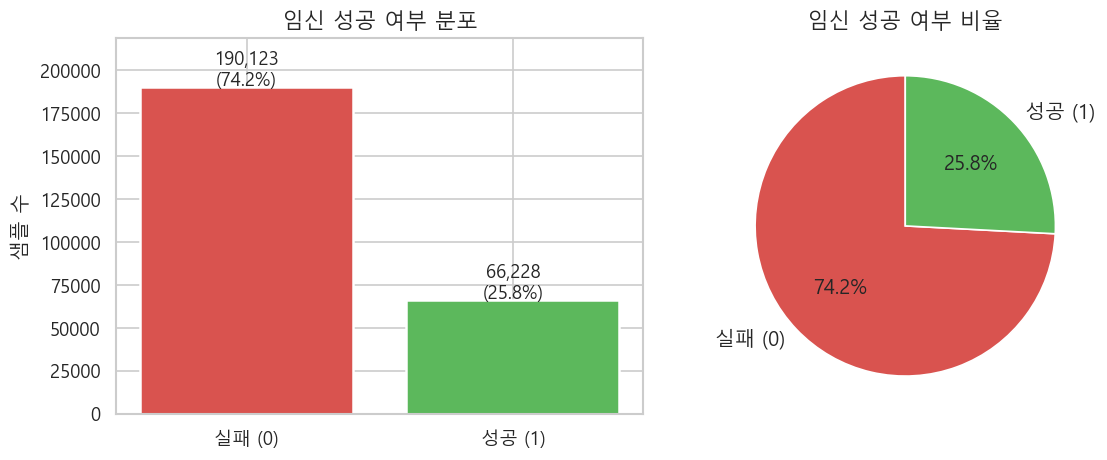

클래스 불균형 비율: 2.87:1 (음성:양성)


In [10]:
counts = train[TARGET].value_counts()
labels = ['실패 (0)', '성공 (1)']
colors = ['#d9534f', '#5cb85c']

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# 바 차트
axes[0].bar(labels, counts.values, color=colors, edgecolor='white', linewidth=1.5)
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 1000, f'{v:,}\n({v/len(train)*100:.1f}%)', ha='center', fontsize=11)
axes[0].set_title('임신 성공 여부 분포', fontsize=13)
axes[0].set_ylabel('샘플 수')
axes[0].set_ylim(0, counts.max() * 1.15)

# 파이 차트
axes[1].pie(counts.values, labels=labels, colors=colors,
            autopct='%1.1f%%', startangle=90, textprops={'fontsize': 12})
axes[1].set_title('임신 성공 여부 비율', fontsize=13)

plt.tight_layout()
plt.savefig('../eda/target_distribution.png', bbox_inches='tight')
plt.show()
print(f"클래스 불균형 비율: {counts[0]/counts[1]:.2f}:1 (음성:양성)")

## 6. 결측치 시각화

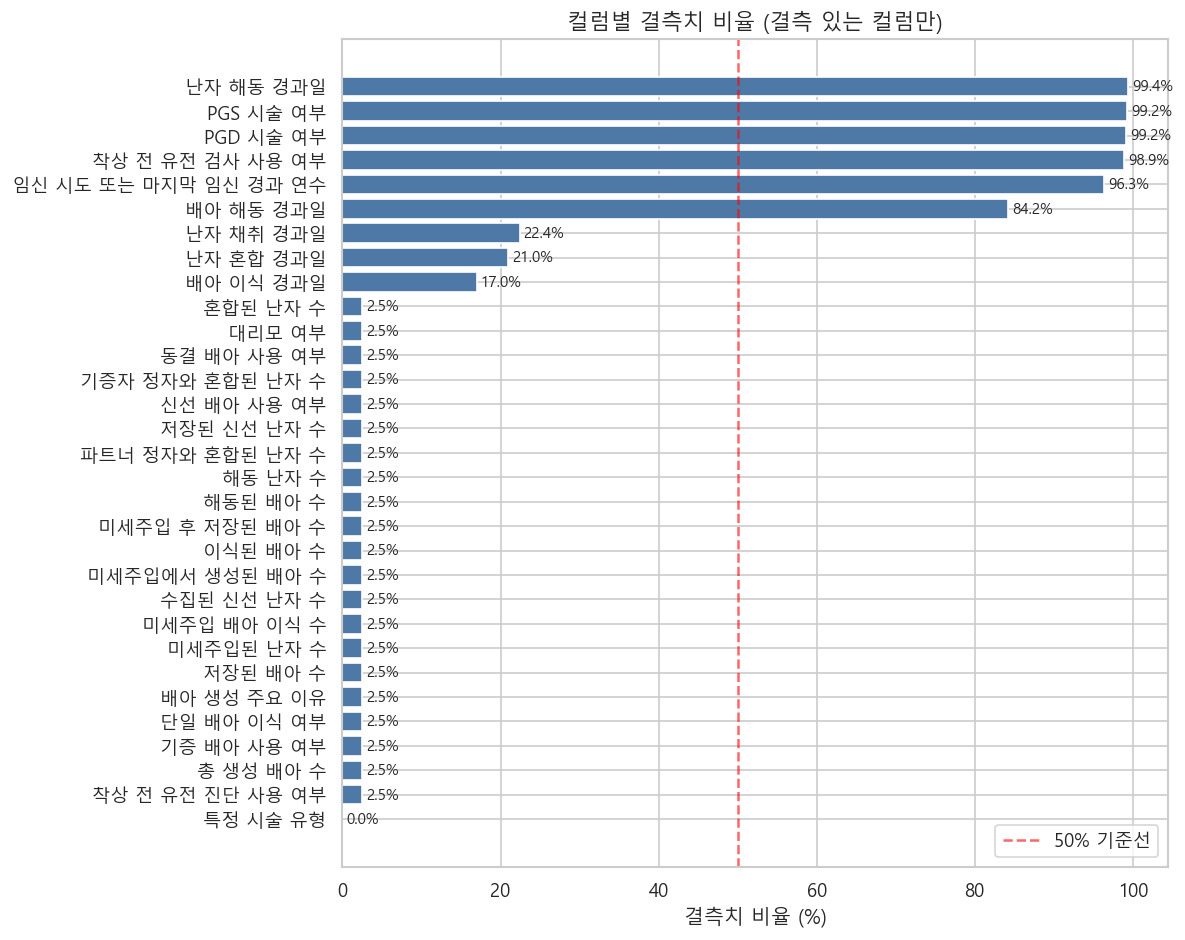

In [11]:
missing_df_sorted = missing_df.sort_values('결측치 비율(%)', ascending=True)

fig, ax = plt.subplots(figsize=(10, 8))
bars = ax.barh(missing_df_sorted.index, missing_df_sorted['결측치 비율(%)'],
               color='#4e79a7', edgecolor='white')

for bar, val in zip(bars, missing_df_sorted['결측치 비율(%)']):
    ax.text(val + 0.5, bar.get_y() + bar.get_height() / 2,
            f'{val:.1f}%', va='center', fontsize=9)

ax.axvline(x=50, color='red', linestyle='--', alpha=0.6, label='50% 기준선')
ax.set_xlabel('결측치 비율 (%)')
ax.set_title('컬럼별 결측치 비율 (결측 있는 컬럼만)', fontsize=13)
ax.legend()
plt.tight_layout()
plt.savefig('../eda/missing_values_bar.png', bbox_inches='tight')
plt.show()

## 7. 주요 범주형 피처 vs 타겟 분석

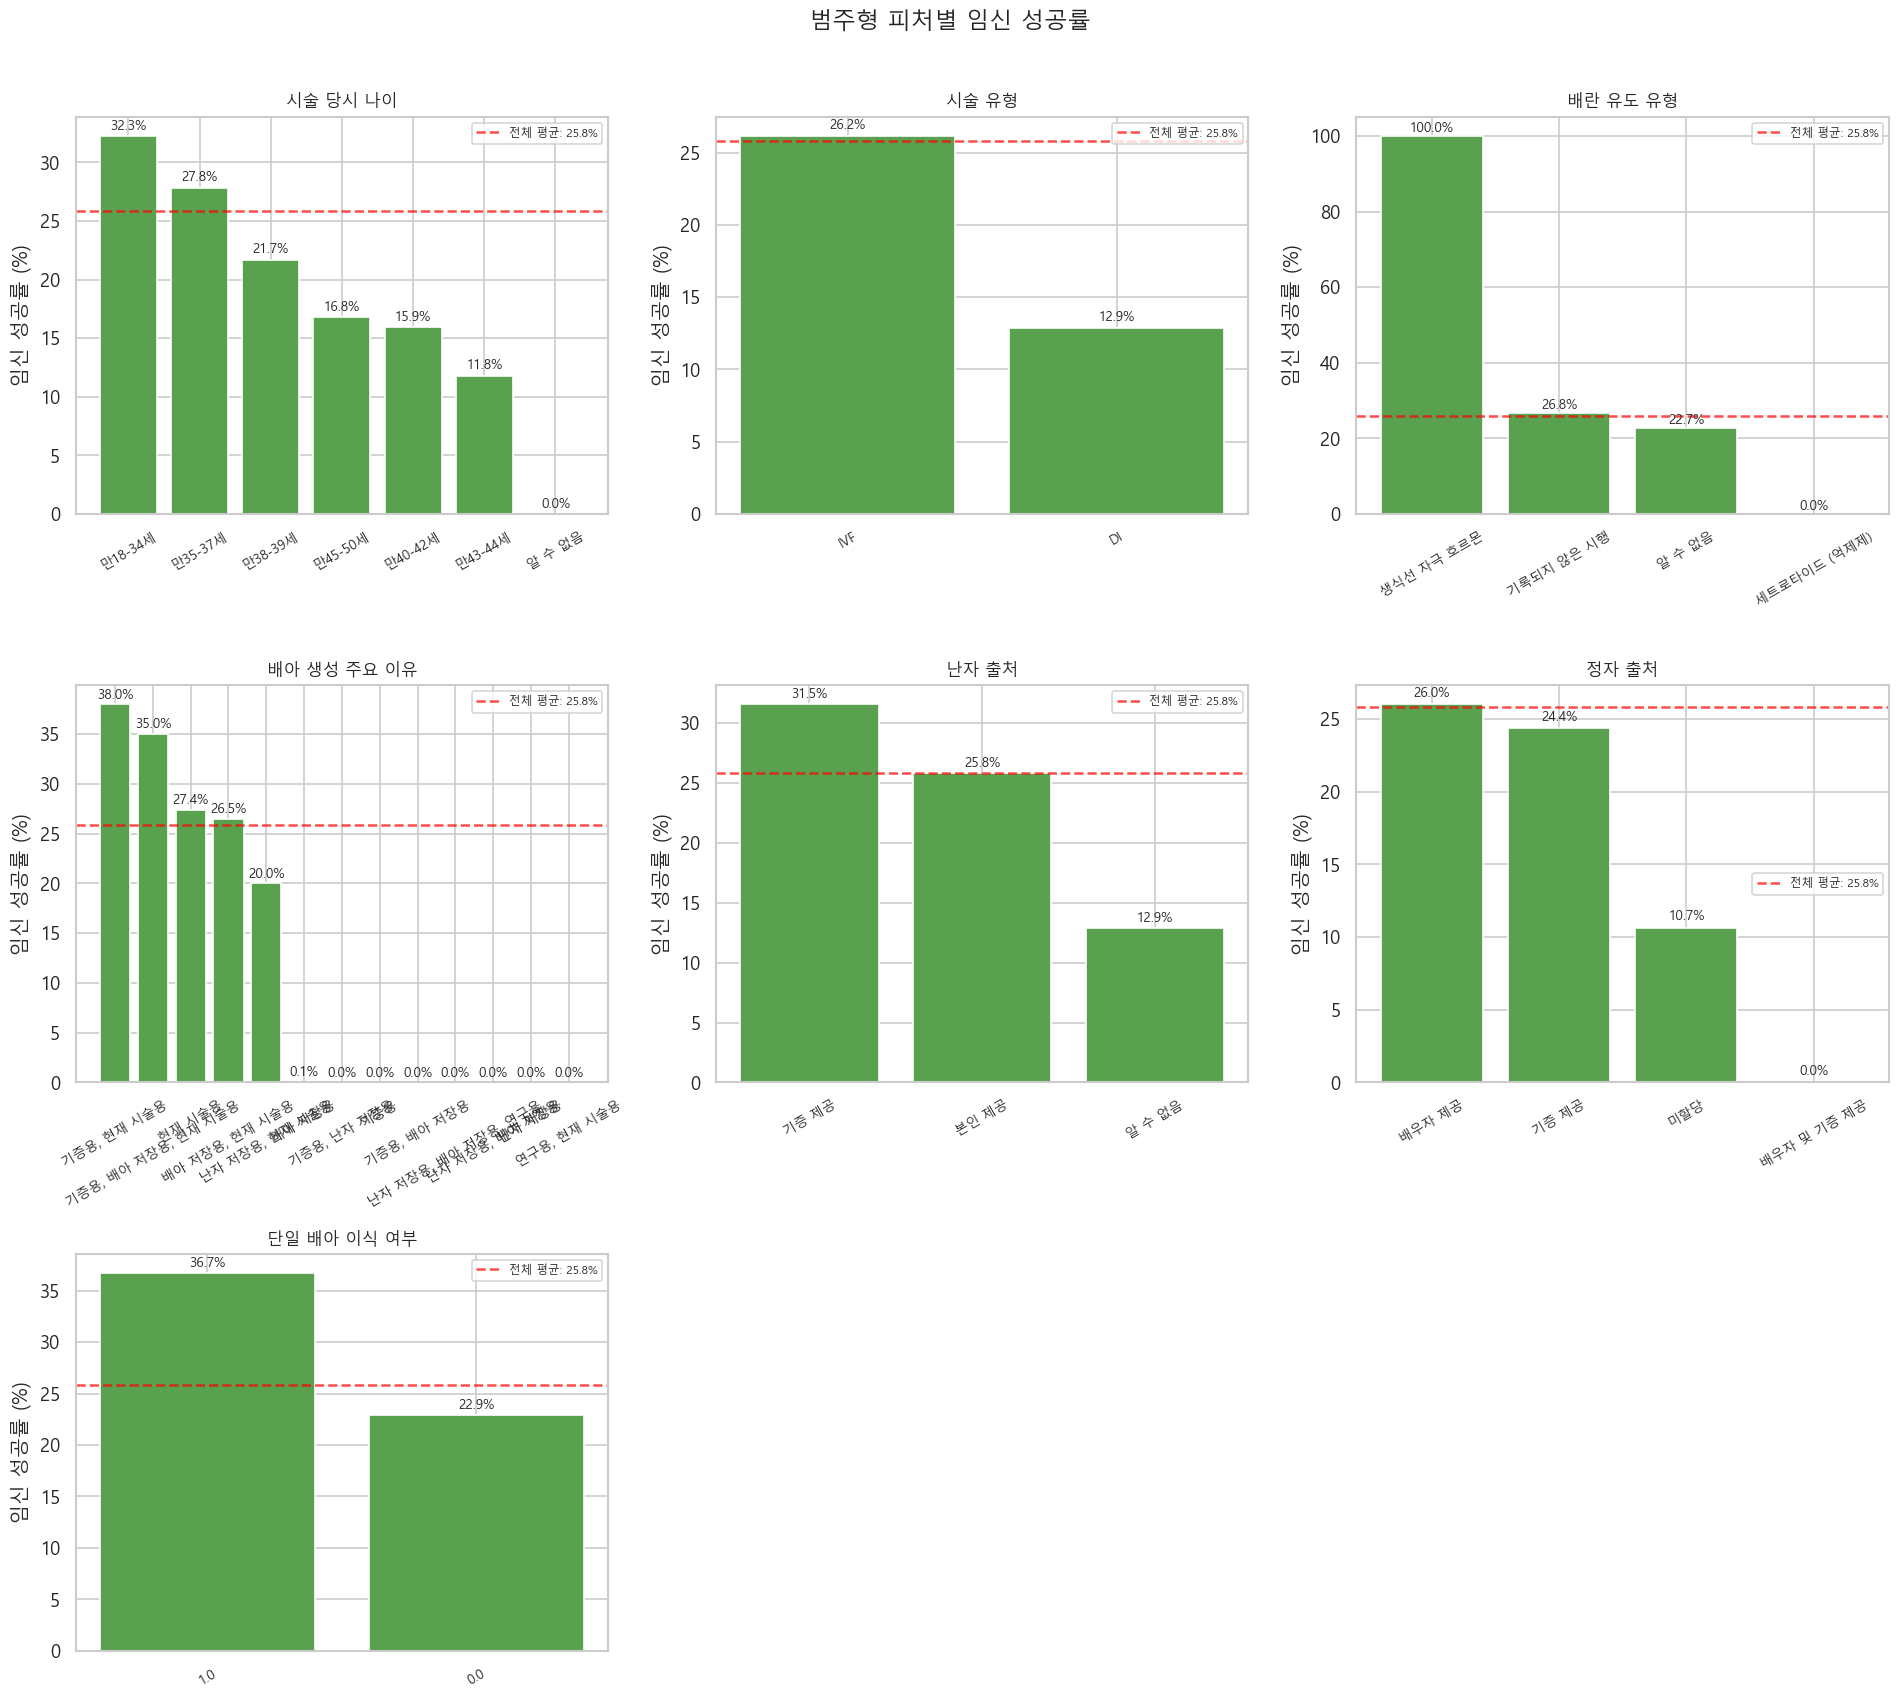

In [12]:
cat_features = ['시술 당시 나이', '시술 유형', '배란 유도 유형', '배아 생성 주요 이유',
                '난자 출처', '정자 출처', '단일 배아 이식 여부']

fig, axes = plt.subplots(3, 3, figsize=(16, 14))
axes = axes.flatten()

for i, col in enumerate(cat_features):
    ax = axes[i]
    rate = (train.groupby(col)[TARGET].mean() * 100).sort_values(ascending=False)
    counts_col = train[col].value_counts()

    bars = ax.bar(rate.index.astype(str), rate.values, color='#59a14f', edgecolor='white')
    for bar, val in zip(bars, rate.values):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
                f'{val:.1f}%', ha='center', va='bottom', fontsize=8)

    ax.axhline(y=train[TARGET].mean() * 100, color='red', linestyle='--',
               alpha=0.7, label=f'전체 평균: {train[TARGET].mean()*100:.1f}%')
    ax.set_title(col, fontsize=10)
    ax.set_ylabel('임신 성공률 (%)')
    ax.tick_params(axis='x', rotation=30, labelsize=8)
    ax.legend(fontsize=7)

# 남는 subplot 숨기기
for j in range(len(cat_features), len(axes)):
    axes[j].set_visible(False)

plt.suptitle('범주형 피처별 임신 성공률', fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig('../eda/categorical_vs_target.png', bbox_inches='tight')
plt.show()

## 8. 수치형 피처 분포 (주요 배아 관련 피처)

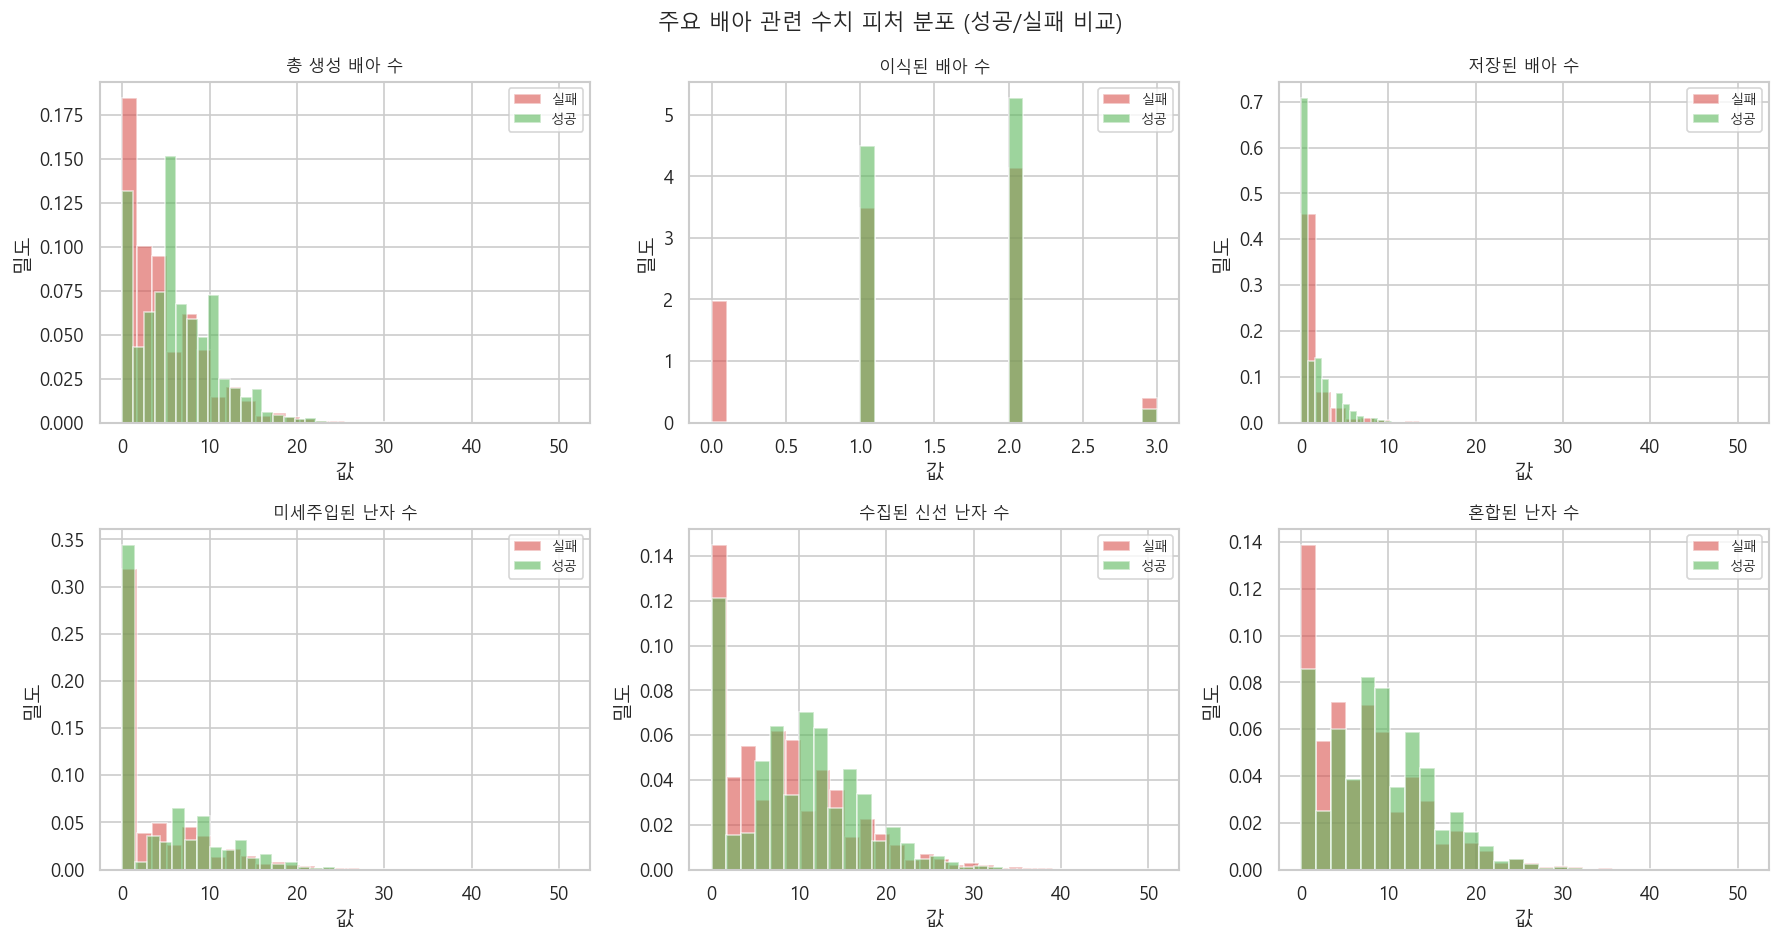

In [13]:
embryo_cols = [
    '총 생성 배아 수', '이식된 배아 수', '저장된 배아 수',
    '미세주입된 난자 수', '수집된 신선 난자 수', '혼합된 난자 수',
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, col in enumerate(embryo_cols):
    ax = axes[i]
    data_0 = train.loc[train[TARGET] == 0, col].dropna()
    data_1 = train.loc[train[TARGET] == 1, col].dropna()

    ax.hist(data_0, bins=30, alpha=0.6, color='#d9534f', label='실패', density=True)
    ax.hist(data_1, bins=30, alpha=0.6, color='#5cb85c', label='성공', density=True)
    ax.set_title(col, fontsize=10)
    ax.set_xlabel('값')
    ax.set_ylabel('밀도')
    ax.legend(fontsize=8)

plt.suptitle('주요 배아 관련 수치 피처 분포 (성공/실패 비교)', fontsize=13)
plt.tight_layout()
plt.savefig('../eda/embryo_distributions.png', bbox_inches='tight')
plt.show()

## 9. 상관관계 분석

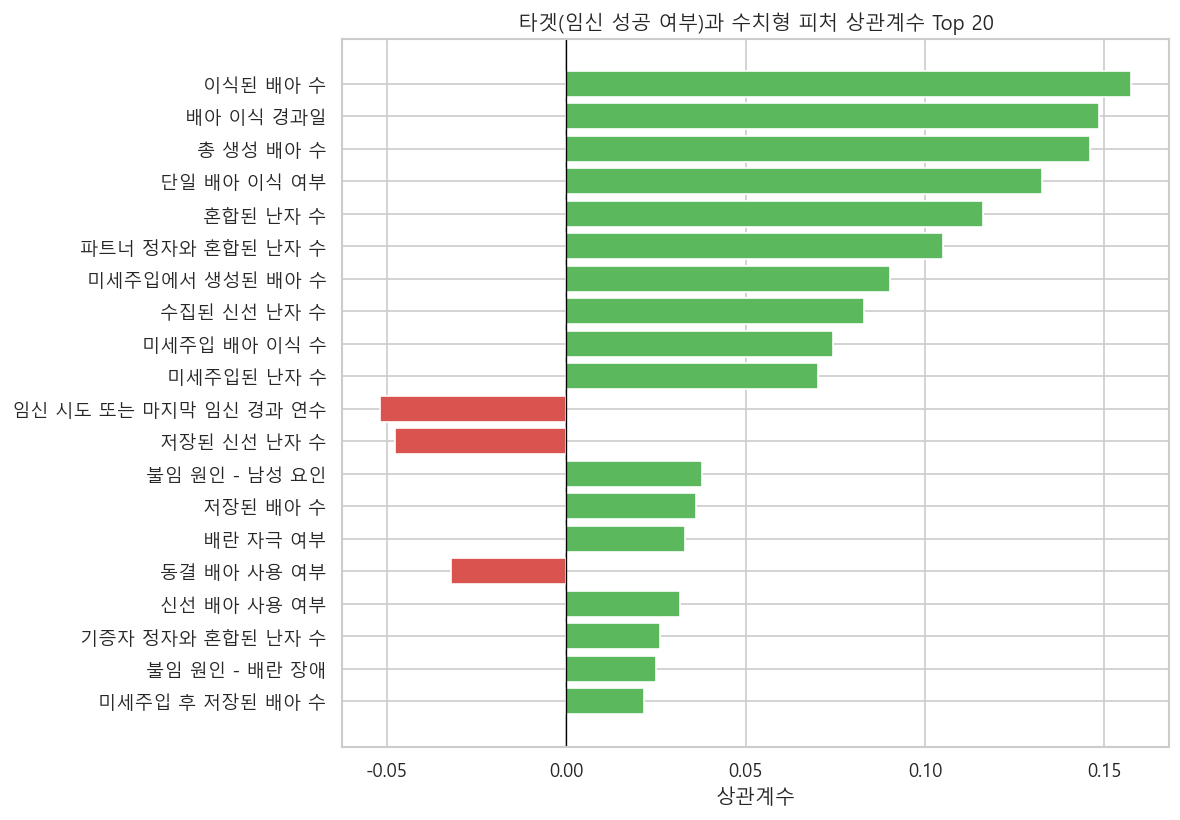

In [14]:
# 수치형 피처 중 타겟과의 상관계수 (포인트-바이시리얼)
num_df = train.select_dtypes(include='number').drop(columns=['ID'], errors='ignore')
corr_with_target = num_df.corr()[TARGET].drop(TARGET).sort_values(key=abs, ascending=False)
corr_with_target.to_csv('../eda/correlation_with_target.csv', encoding='utf-8-sig', header=['상관계수'])

# 상위 20개 시각화
top_corr = corr_with_target.head(20)
colors = ['#5cb85c' if v > 0 else '#d9534f' for v in top_corr.values]

fig, ax = plt.subplots(figsize=(10, 7))
bars = ax.barh(top_corr.index[::-1], top_corr.values[::-1], color=colors[::-1], edgecolor='white')
ax.axvline(x=0, color='black', linewidth=0.8)
ax.set_xlabel('상관계수')
ax.set_title('타겟(임신 성공 여부)과 수치형 피처 상관계수 Top 20', fontsize=12)
plt.tight_layout()
plt.savefig('../eda/correlation_with_target.png', bbox_inches='tight')
plt.show()

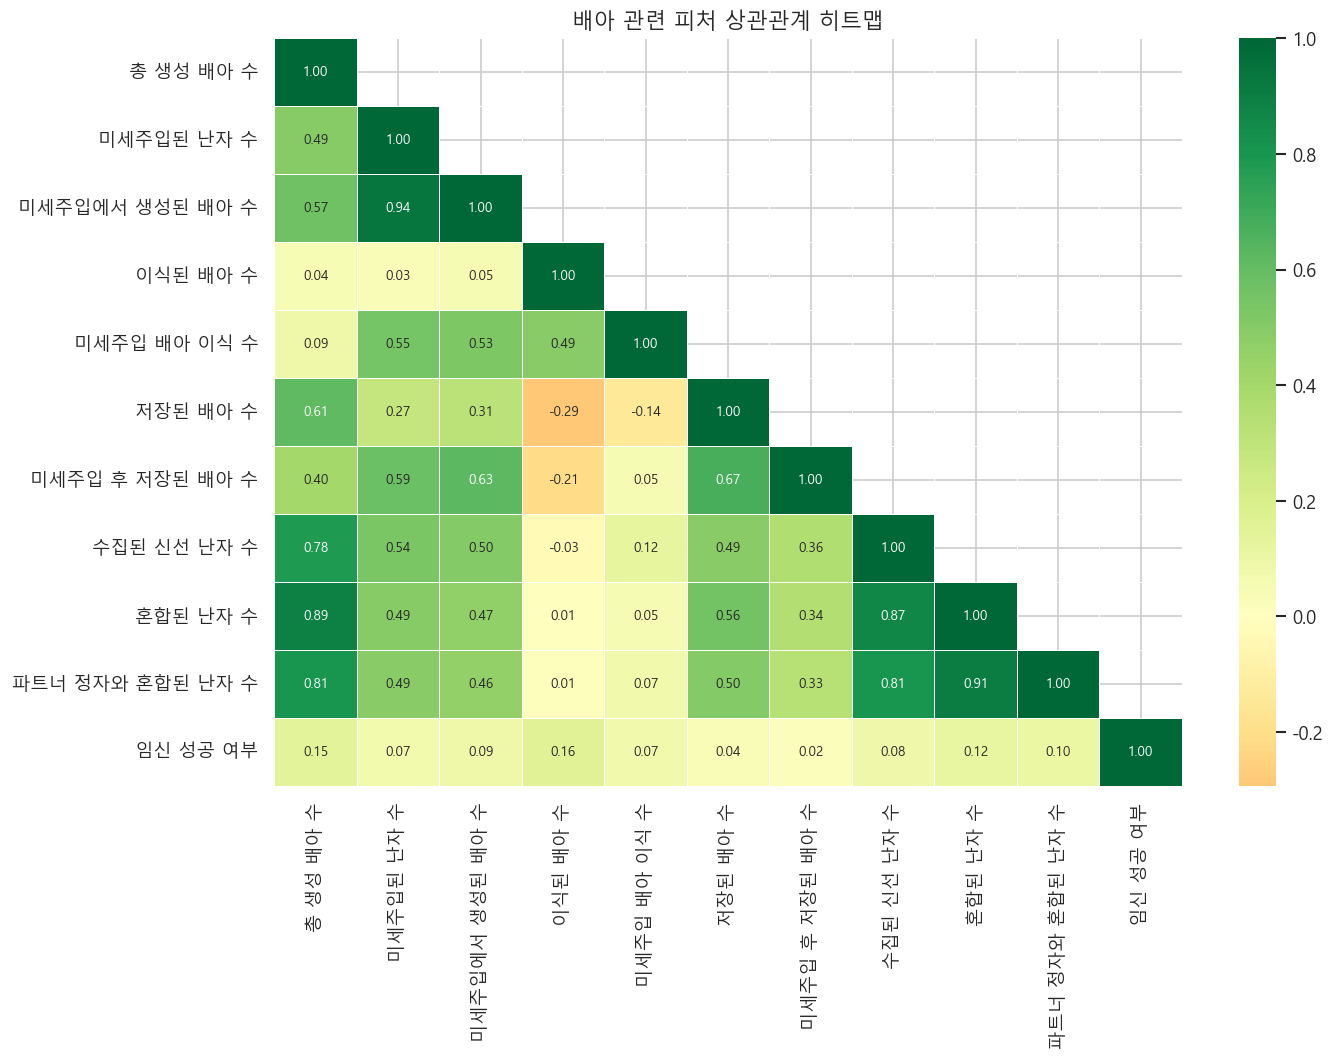

In [15]:
# 수치형 피처 간 상관관계 히트맵 (배아 관련 피처 집중)
embryo_num_cols = [
    '총 생성 배아 수', '미세주입된 난자 수', '미세주입에서 생성된 배아 수',
    '이식된 배아 수', '미세주입 배아 이식 수', '저장된 배아 수',
    '미세주입 후 저장된 배아 수', '수집된 신선 난자 수', '혼합된 난자 수',
    '파트너 정자와 혼합된 난자 수', TARGET
]
corr_matrix = train[embryo_num_cols].corr()

fig, ax = plt.subplots(figsize=(12, 9))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='RdYlGn',
            center=0, linewidths=0.5, ax=ax, mask=mask,
            annot_kws={'size': 8})
ax.set_title('배아 관련 피처 상관관계 히트맵', fontsize=13)
plt.tight_layout()
plt.savefig('../eda/correlation_heatmap.png', bbox_inches='tight')
plt.show()

## 10. 이상치 탐지 (IQR 기반)

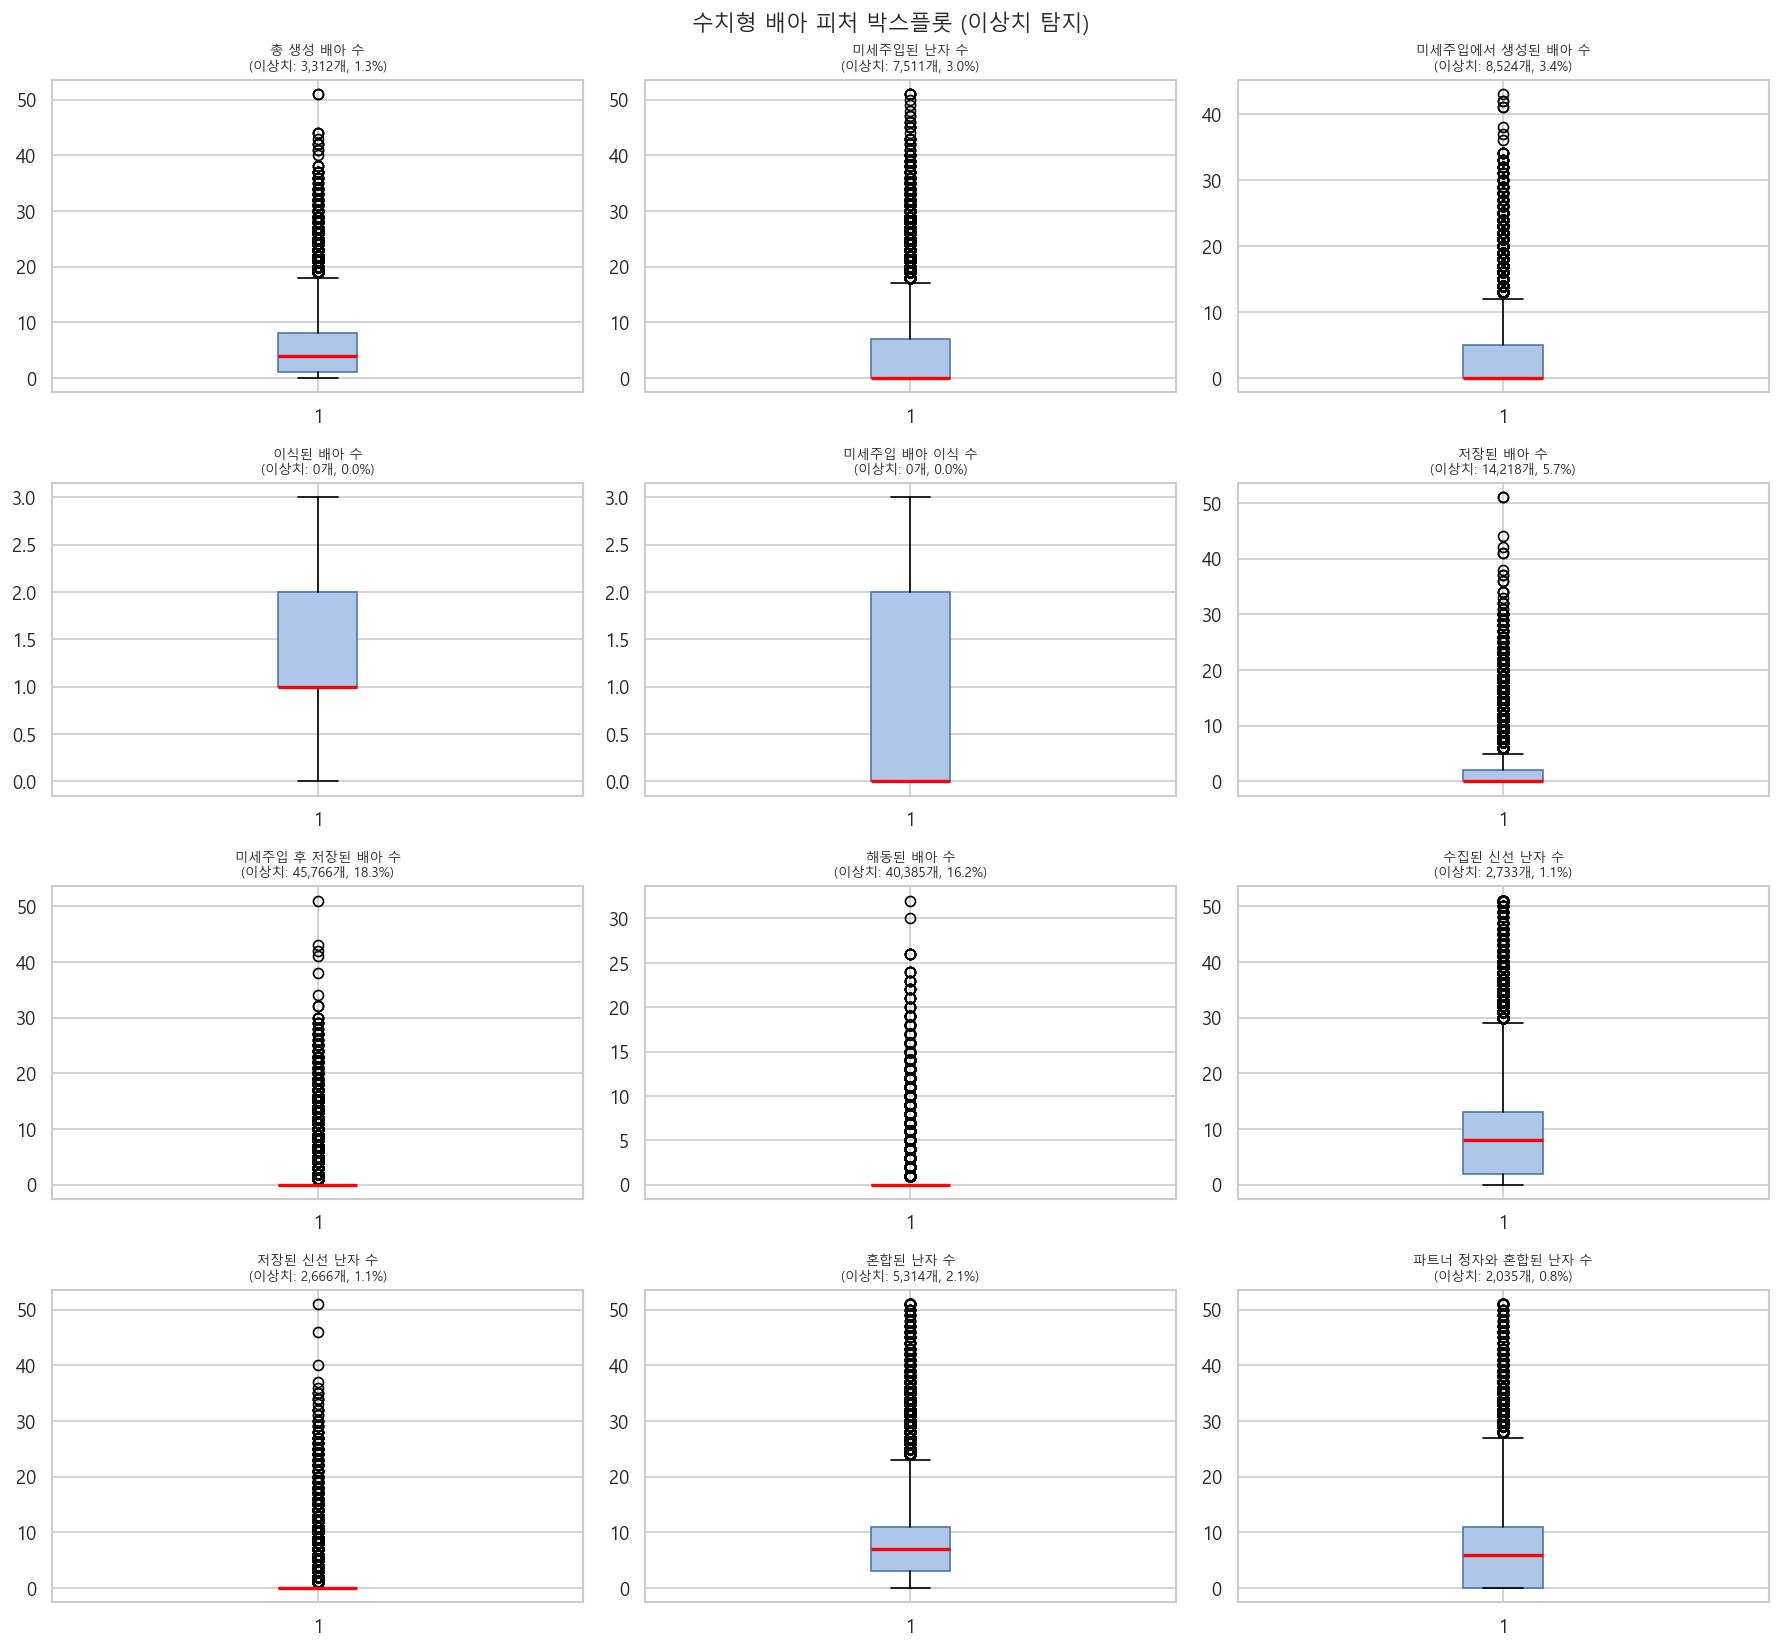

                  이상치 수  이상치 비율(%)
컬럼                                
총 생성 배아 수          3312       1.32
미세주입된 난자 수         7511       3.00
미세주입에서 생성된 배아 수    8524       3.41
이식된 배아 수              0       0.00
미세주입 배아 이식 수          0       0.00
저장된 배아 수          14218       5.69
미세주입 후 저장된 배아 수   45766      18.30
해동된 배아 수          40385      16.15
수집된 신선 난자 수        2733       1.09
저장된 신선 난자 수        2666       1.07
혼합된 난자 수           5314       2.13
파트너 정자와 혼합된 난자 수   2035       0.81


In [16]:
# 실제 수치형인 컬럼만 이상치 분석 (시술 횟수 등 "0회" 문자열 컬럼 제외)
num_only_cols = [
    '총 생성 배아 수', '미세주입된 난자 수', '미세주입에서 생성된 배아 수',
    '이식된 배아 수', '미세주입 배아 이식 수', '저장된 배아 수',
    '미세주입 후 저장된 배아 수', '해동된 배아 수', '수집된 신선 난자 수',
    '저장된 신선 난자 수', '혼합된 난자 수', '파트너 정자와 혼합된 난자 수',
]

# 실제로 수치형인 컬럼만 필터링 (혹시 모를 문자열 컬럼 방어)
num_train = train.select_dtypes(include='number')
count_cols = [c for c in num_only_cols if c in num_train.columns]

n_cols = len(count_cols)
n_rows = (n_cols + 2) // 3
fig, axes = plt.subplots(n_rows, 3, figsize=(15, n_rows * 3.5))
axes = axes.flatten()

outlier_summary = []
for i, col in enumerate(count_cols):
    ax = axes[i]
    series = train[col].dropna()

    Q1, Q3 = series.quantile(0.25), series.quantile(0.75)
    IQR = Q3 - Q1
    upper = Q3 + 1.5 * IQR
    n_outliers = int((series > upper).sum())
    outlier_pct = n_outliers / len(series) * 100
    outlier_summary.append({'컬럼': col, '이상치 수': n_outliers, '이상치 비율(%)': round(outlier_pct, 2)})

    ax.boxplot(series, vert=True, patch_artist=True,
               boxprops=dict(facecolor='#aec6e8', color='#4e79a7'),
               medianprops=dict(color='red', linewidth=2))
    ax.set_title(f'{col}\n(이상치: {n_outliers:,}개, {outlier_pct:.1f}%)', fontsize=8)

for j in range(n_cols, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('수치형 배아 피처 박스플롯 (이상치 탐지)', fontsize=13)
plt.tight_layout()
plt.savefig('../eda/outlier_boxplots.png', bbox_inches='tight')
plt.show()

outlier_df = pd.DataFrame(outlier_summary).set_index('컬럼')
outlier_df.to_csv('../eda/outlier_summary.csv', encoding='utf-8-sig')
print(outlier_df)

## 11. 시술 횟수 누적에 따른 임신 성공률 추이

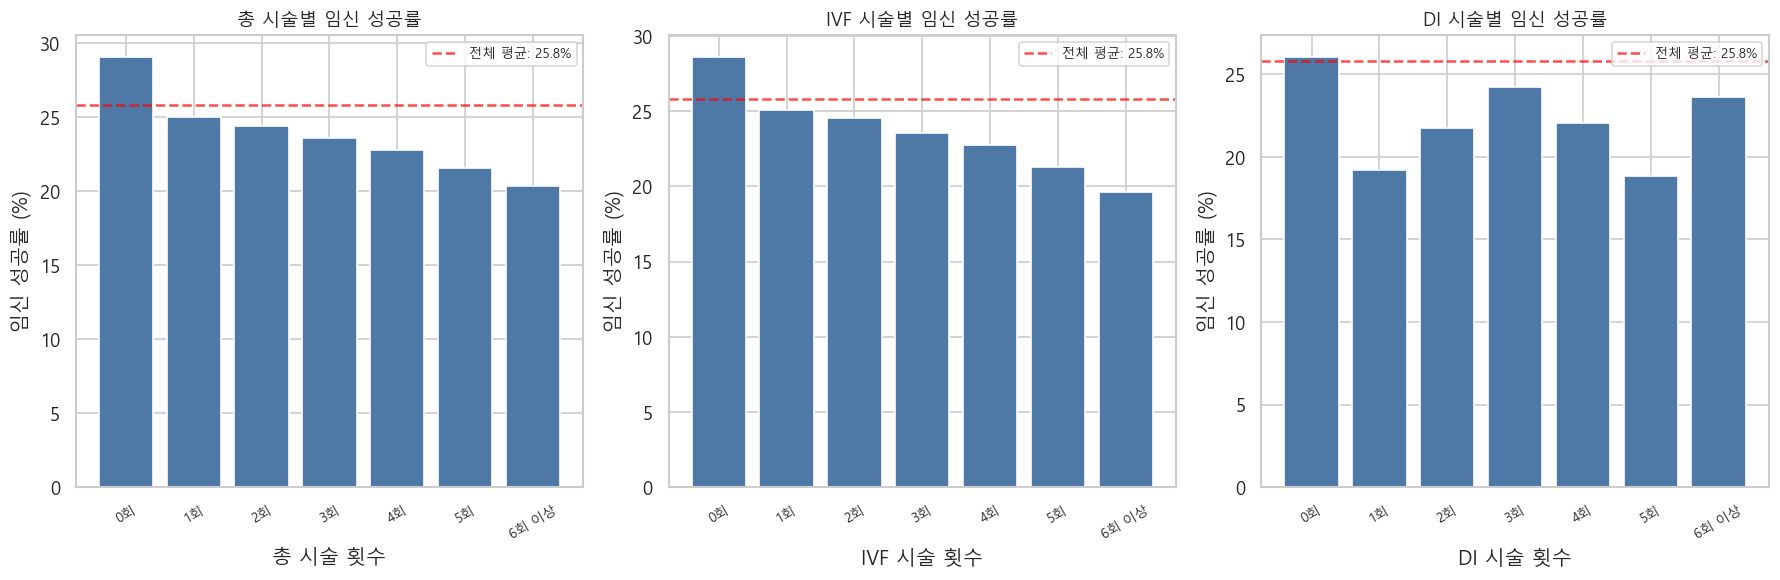

In [17]:
attempt_cols = {
    '총 시술 횟수': '총 시술',
    'IVF 시술 횟수': 'IVF 시술',
    'DI 시술 횟수': 'DI 시술',
}

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, (col, label) in zip(axes, attempt_cols.items()):
    # 범주형 값 정렬 (예: "0회", "1회", ...) → 숫자 기준으로 정렬
    group = train.groupby(col)[TARGET].agg(['mean', 'count']).reset_index()
    group.columns = [col, 'success_rate', 'count']

    # 숫자 추출 후 정렬
    group['sort_key'] = group[col].str.extract(r'(\d+)').astype(float)
    group = group.sort_values('sort_key')

    ax.bar(group[col], group['success_rate'] * 100, color='#4e79a7', edgecolor='white')
    ax.axhline(y=train[TARGET].mean() * 100, color='red', linestyle='--',
               alpha=0.7, label=f'전체 평균: {train[TARGET].mean()*100:.1f}%')
    ax.set_title(f'{label}별 임신 성공률', fontsize=11)
    ax.set_xlabel(col)
    ax.set_ylabel('임신 성공률 (%)')
    ax.tick_params(axis='x', rotation=30, labelsize=8)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig('../eda/attempt_vs_success_rate.png', bbox_inches='tight')
plt.show()

## 12. 불임 원인 플래그 분석

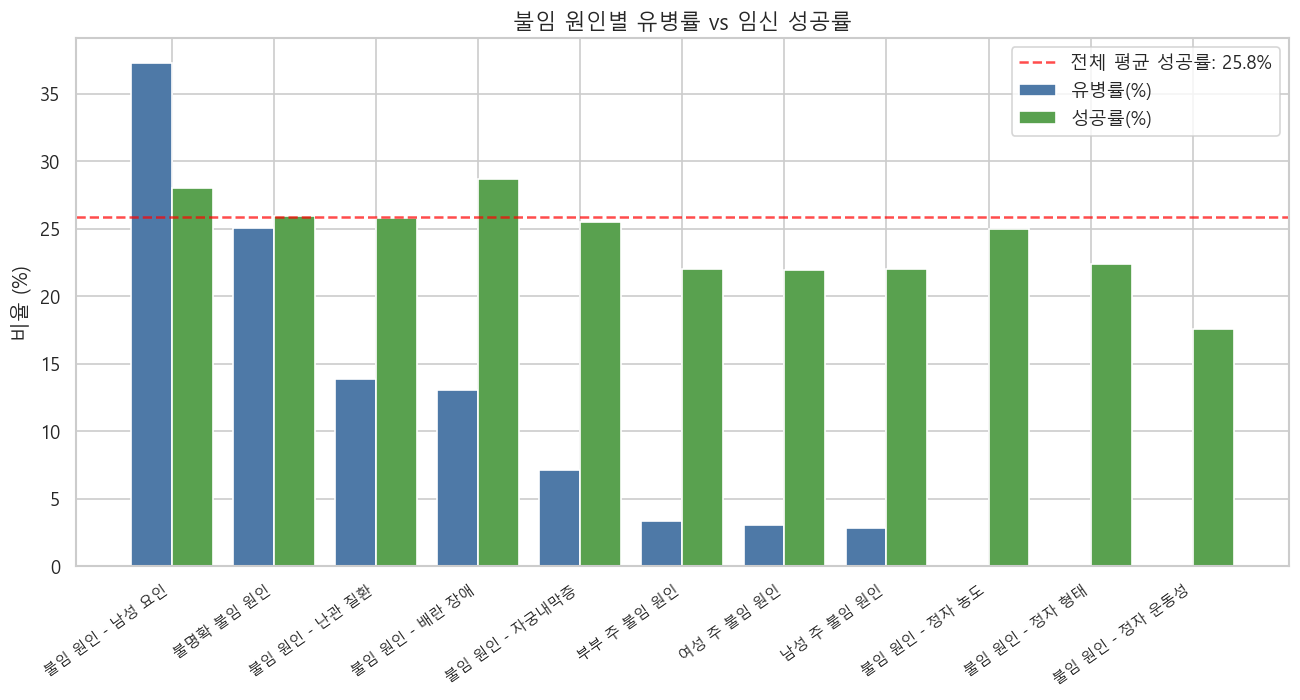

In [18]:
infertility_cols = [
    '남성 주 불임 원인', '여성 주 불임 원인', '부부 주 불임 원인', '불명확 불임 원인',
    '불임 원인 - 난관 질환', '불임 원인 - 남성 요인', '불임 원인 - 배란 장애',
    '불임 원인 - 자궁내막증', '불임 원인 - 정자 농도', '불임 원인 - 정자 운동성',
    '불임 원인 - 정자 형태',
]

# 각 불임 원인 플래그별 유병률(%) vs 임신 성공률(%)
prevalence = (train[infertility_cols].mean() * 100).rename('유병률(%)')
success_rate = (
    train.groupby(lambda _: 0)[infertility_cols + [TARGET]]
    .apply(lambda df: pd.Series({
        col: df.loc[df[col] == 1, TARGET].mean() * 100
        for col in infertility_cols
    }))
    .iloc[0]
    .rename('성공률(%)')
)

summary = pd.concat([prevalence, success_rate], axis=1).sort_values('유병률(%)', ascending=False)

fig, ax = plt.subplots(figsize=(11, 6))
x = np.arange(len(summary))
w = 0.4
ax.bar(x - w/2, summary['유병률(%)'], width=w, label='유병률(%)', color='#4e79a7')
ax.bar(x + w/2, summary['성공률(%)'], width=w, label='성공률(%)', color='#59a14f')
ax.axhline(y=train[TARGET].mean() * 100, color='red', linestyle='--',
           alpha=0.7, label=f'전체 평균 성공률: {train[TARGET].mean()*100:.1f}%')
ax.set_xticks(x)
ax.set_xticklabels(summary.index, rotation=35, ha='right', fontsize=9)
ax.set_ylabel('비율 (%)')
ax.set_title('불임 원인별 유병률 vs 임신 성공률', fontsize=13)
ax.legend()
plt.tight_layout()
plt.savefig('../eda/infertility_cause_analysis.png', bbox_inches='tight')
plt.show()

## 13. EDA 요약 및 모델링 전 시사점

In [19]:
print("=" * 60)
print("📊 EDA 요약")
print("=" * 60)

print(f"\n[데이터 기본 정보]")
print(f"  - 훈련 샘플: {len(train):,}건 / 테스트 샘플: {len(test):,}건")
print(f"  - 피처 수: {train.shape[1] - 2}개 (ID, 타겟 제외)")
print(f"  - 타겟 불균형: 실패 {(train[TARGET]==0).mean()*100:.1f}% / 성공 {(train[TARGET]==1).mean()*100:.1f}%")

high_missing = missing_df[missing_df['결측치 비율(%)'] >= 50]
print(f"\n[결측치 현황]")
print(f"  - 결측 있는 컬럼: {len(missing_df)}개")
print(f"  - 50% 이상 결측: {len(high_missing)}개 → 제거 또는 별도 플래그 처리 고려")
for col, row in high_missing.iterrows():
    print(f"      {col}: {row['결측치 비율(%)']:.1f}%")

print(f"\n[모델링 시사점]")
print("  1. 클래스 불균형 처리 필요 (SMOTE, class_weight, threshold 조정)")
print("  2. 고결측 컬럼(PGD/PGS, 경과일 등)은 'has_value' 이진 피처로 대체 검토")
print("  3. 이식된 배아 수, 수집 난자 수 → 타겟 상관 높음, 핵심 피처")
print("  4. 나이 그룹별 성공률 차이 큼 → 나이 피처 중요도 높음")
print("  5. IVF/DI 구분이 결과에 큰 영향 → 시술 유형 분리 모델도 고려")
print("  6. 이상치(극단값) 있는 배아 수 피처 → 클리핑 또는 로그 변환 고려")

📊 EDA 요약

[데이터 기본 정보]
  - 훈련 샘플: 256,351건 / 테스트 샘플: 90,067건
  - 피처 수: 67개 (ID, 타겟 제외)
  - 타겟 불균형: 실패 74.2% / 성공 25.8%

[결측치 현황]
  - 결측 있는 컬럼: 31개
  - 50% 이상 결측: 6개 → 제거 또는 별도 플래그 처리 고려
      난자 해동 경과일: 99.4%
      PGS 시술 여부: 99.2%
      PGD 시술 여부: 99.2%
      착상 전 유전 검사 사용 여부: 98.9%
      임신 시도 또는 마지막 임신 경과 연수: 96.3%
      배아 해동 경과일: 84.2%

[모델링 시사점]
  1. 클래스 불균형 처리 필요 (SMOTE, class_weight, threshold 조정)
  2. 고결측 컬럼(PGD/PGS, 경과일 등)은 'has_value' 이진 피처로 대체 검토
  3. 이식된 배아 수, 수집 난자 수 → 타겟 상관 높음, 핵심 피처
  4. 나이 그룹별 성공률 차이 큼 → 나이 피처 중요도 높음
  5. IVF/DI 구분이 결과에 큰 영향 → 시술 유형 분리 모델도 고려
  6. 이상치(극단값) 있는 배아 수 피처 → 클리핑 또는 로그 변환 고려
